In [6]:
from script import *

In [7]:
device = "cuda"
model = ResNetUNet(num_classes=2, pretrained=True).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=255)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
)

train_dataset = PenguinDataset("dataset/train")
valid_dataset = PenguinDataset("dataset/valid")

duplicate_train_name = (
    "00000138_jpg.rf.a0a6ee1db35ff8e042928ae5a15597d9.jpg"
)

train_indices = [
    index
    for index, info in enumerate(train_dataset.images)
    if info["file_name"] != duplicate_train_name
]

assert len(train_dataset) - len(train_indices) == 1

train_subset = Subset(train_dataset, train_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
)

output_dir = Path("runs/penguin_baseline")
output_dir.mkdir(parents=True, exist_ok=True)

In [8]:
trainer = Trainer(
    model,
    train_loader,
    valid_loader,
    criterion,
    optimizer,
    device,
    output_dir,
)

In [9]:
trainer.fit(10)

[logs] === epoch 01 ===
 train loss: 0.2996
 valid loss: 0.2657
 penguin iou: 0.7777

[save] === best checkpoint saved ===

[logs] === epoch 02 ===
 train loss: 0.1674
 valid loss: 0.2066
 penguin iou: 0.7738

[logs] === epoch 03 ===
 train loss: 0.1096
 valid loss: 0.1528
 penguin iou: 0.8310

[save] === best checkpoint saved ===

[logs] === epoch 04 ===
 train loss: 0.0774
 valid loss: 0.3036
 penguin iou: 0.7020

[logs] === epoch 05 ===
 train loss: 0.1339
 valid loss: 0.2064
 penguin iou: 0.7749

[logs] === epoch 06 ===
 train loss: 0.0724
 valid loss: 0.1275
 penguin iou: 0.8599

[save] === best checkpoint saved ===

[logs] === epoch 07 ===
 train loss: 0.0501
 valid loss: 0.1298
 penguin iou: 0.8675

[save] === best checkpoint saved ===

[logs] === epoch 08 ===
 train loss: 0.0396
 valid loss: 0.1203
 penguin iou: 0.8766

[save] === best checkpoint saved ===

[logs] === epoch 09 ===
 train loss: 0.0340
 valid loss: 0.1240
 penguin iou: 0.8824

[save] === best checkpoint saved ===

---

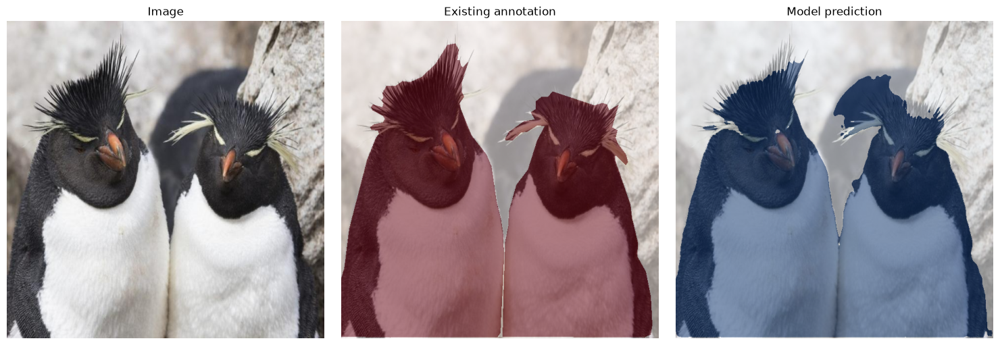

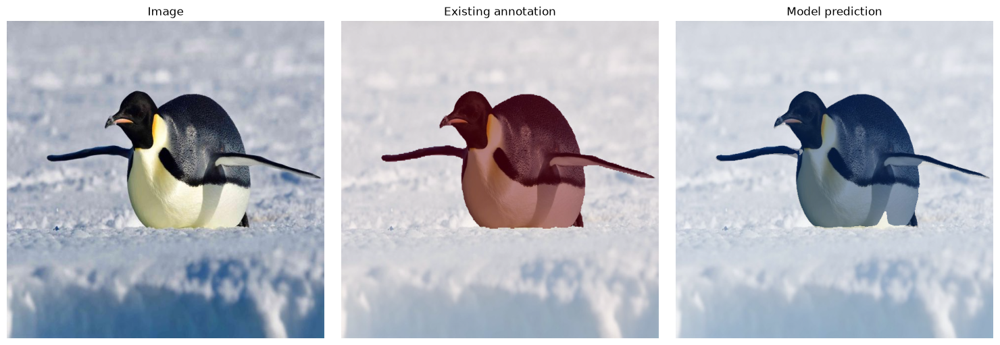

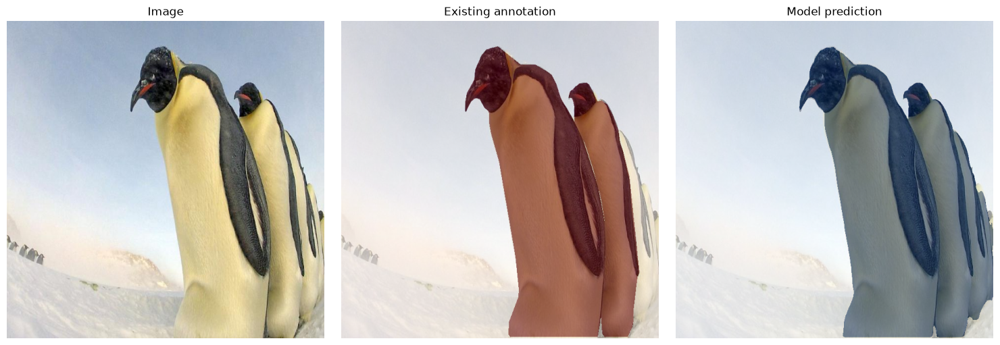

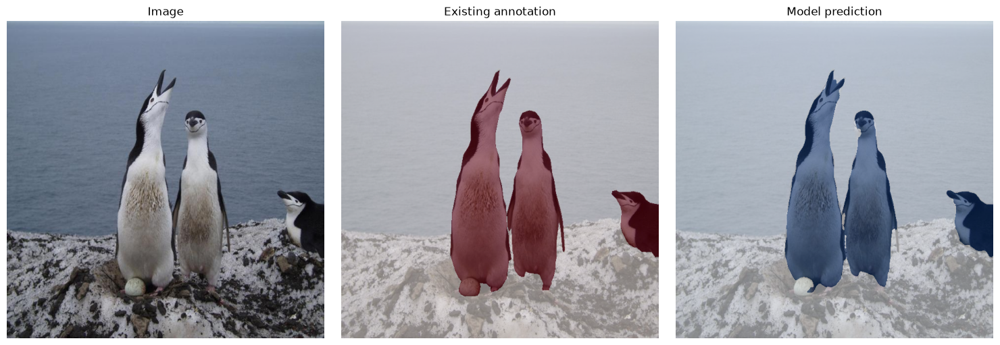

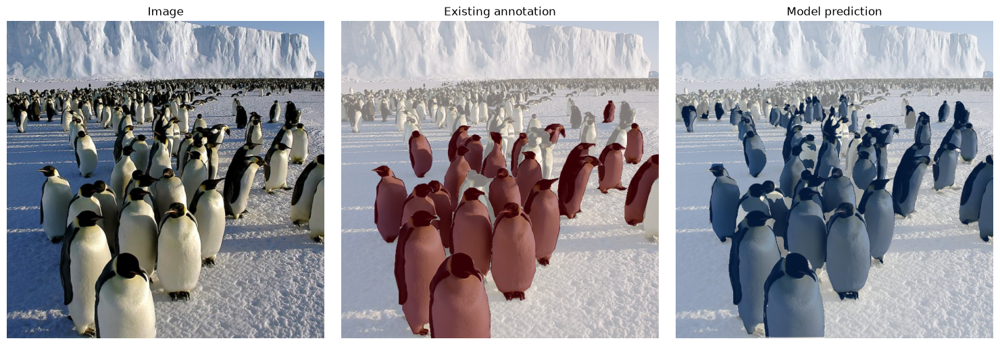

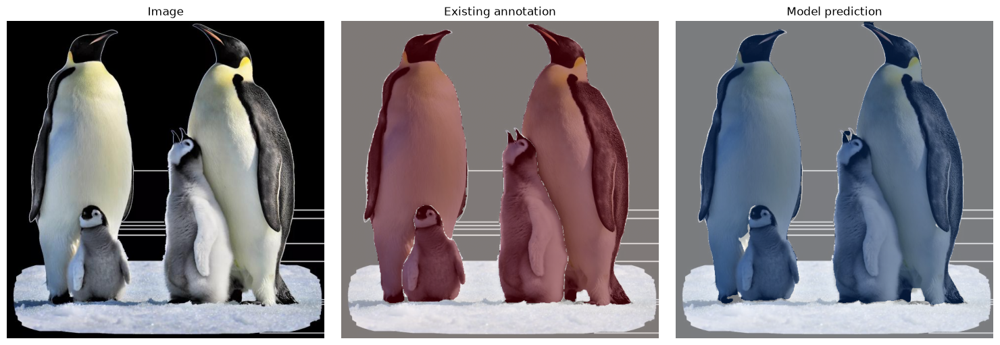

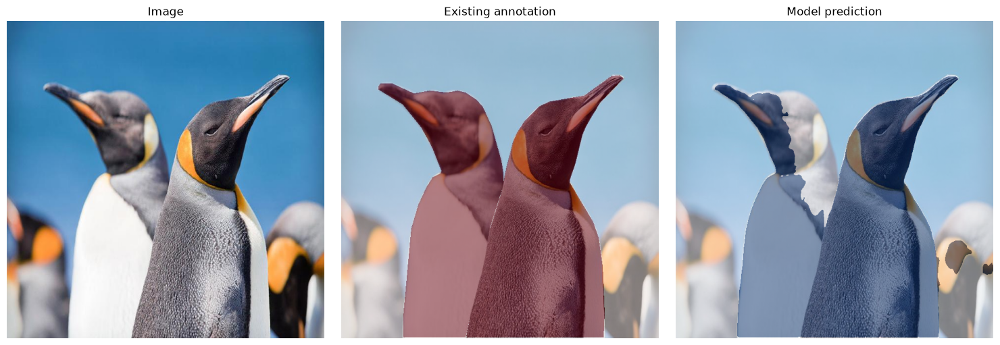

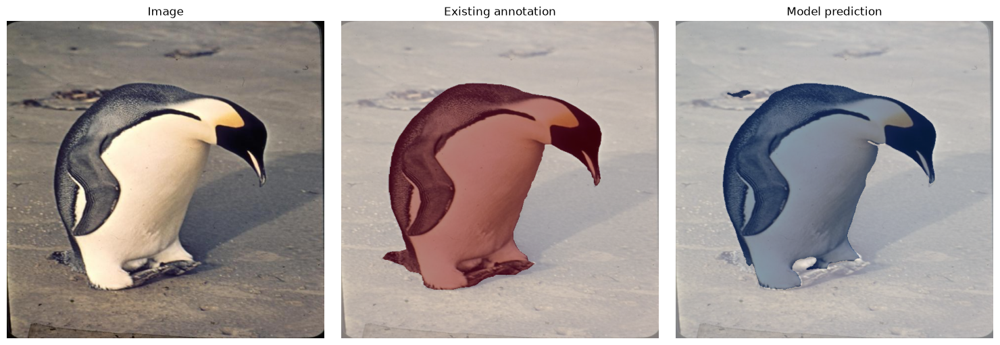

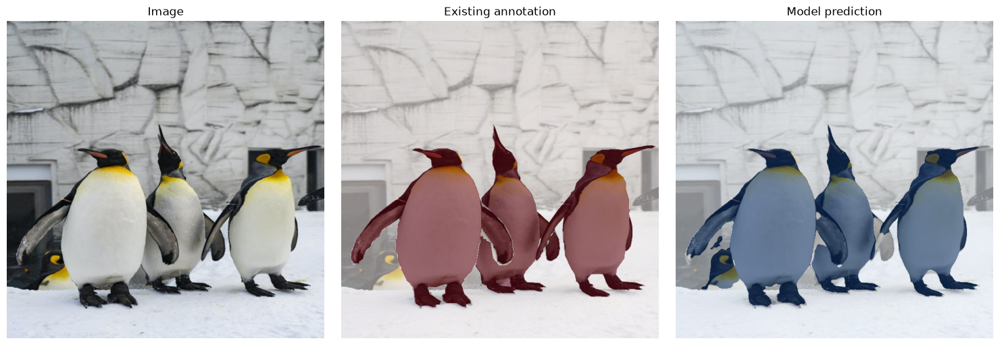

In [10]:
for index in range(9):
    show_validation_prediction(trainer.model, valid_dataset, index, device)

# Experiment 1: Overlapping Sliding-window Inference

In [1]:
from pathlib import Path, WindowsPath
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image, ImageOps

import torch
import torch.nn.functional as F
from torchvision.transforms import functional as TF

#
num_examples = 2

# Project paths
ROOT = Path(r"E:\workspace\pyscripts\semseg")
CHECKPOINT_PATH = ROOT / "runs" / "penguin_baseline" / "best.pt"
TEST_DIR = ROOT / "examples"

# Make sure Python can import the project's script.py.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from script import ResNetUNet


# Tiled inference settings
TILE_SIZE = 640
STRIDE = 480

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Project:", ROOT)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Test directory exists:", TEST_DIR.exists())
print("Device:", device)

Project: E:\workspace\pyscripts\semseg
Checkpoint exists: True
Test directory exists: True
Device: cuda


In [2]:
# The current checkpoint contains WindowsPath metadata.
with torch.serialization.safe_globals([WindowsPath]):
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )

print("Checkpoint epoch:", checkpoint.get("epoch"))
print("Recorded validation IoU:", checkpoint.get("valid_penguin_iou"))
print("Number of classes:", checkpoint.get("num_classes"))

if checkpoint.get("num_classes") != 2:
    raise ValueError("This inference code expects a 2-class checkpoint.")

# The saved checkpoint already contains the trained encoder weights.
model = ResNetUNet(
    num_classes=2,
    pretrained=False,
)

model.load_state_dict(checkpoint["model_state"])
model = model.to(device)
model.eval()

# The optimizer state is not needed for inference.
del checkpoint

print("Model loaded.")

Checkpoint epoch: 9
Recorded validation IoU: 0.8823695749227813
Number of classes: 2
Model loaded.


In [3]:
def get_tile_starts(length, tile_size, stride):
    """Calculate tile positions so the far edge is also covered."""
    if length <= tile_size:
        return [0]

    starts = list(range(0, length - tile_size + 1, stride))
    last_start = length - tile_size

    if starts[-1] != last_start:
        starts.append(last_start)

    return starts


@torch.inference_mode()
def predict_with_tiles(image):
    """
    Return:
        prediction: [H, W] numpy array, 0=background, 1=penguin
        tiles: actual tile rectangles used during inference
    """
    if not 0 < STRIDE <= TILE_SIZE:
        raise ValueError("STRIDE must satisfy 0 < STRIDE <= TILE_SIZE")

    image = image.convert("RGB")
    width, height = image.size

    x_starts = get_tile_starts(width, TILE_SIZE, STRIDE)
    y_starts = get_tile_starts(height, TILE_SIZE, STRIDE)

    # Full-image accumulators stay on CPU.
    logit_sum = torch.zeros((2, height, width), dtype=torch.float32)
    count = torch.zeros((height, width), dtype=torch.float32)

    tiles = []
    total_tiles = len(x_starts) * len(y_starts)

    print(f"  Number of tiles: {total_tiles}")

    for top in y_starts:
        for left in x_starts:
            patch_width = min(TILE_SIZE, width - left)
            patch_height = min(TILE_SIZE, height - top)

            patch = image.crop(
                (
                    left,
                    top,
                    left + patch_width,
                    top + patch_height,
                )
            )

            # RGB image -> tensor in [0, 1].
            patch_tensor = TF.to_tensor(patch)

            # Pad images smaller than one tile on the right and bottom.
            patch_tensor = F.pad(
                patch_tensor,
                (
                    0, TILE_SIZE - patch_width,
                    0, TILE_SIZE - patch_height,
                ),
            )

            # Same normalization used by PenguinDataset.
            patch_tensor = TF.normalize(
                patch_tensor,
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225],
            )

            patch_tensor = patch_tensor.unsqueeze(0).to(device)

            # Model output: [1, 2, TILE_SIZE, TILE_SIZE].
            logits = model(patch_tensor)[0].float().cpu()

            # Remove the part corresponding to padding.
            logits = logits[:, :patch_height, :patch_width]

            logit_sum[
                :,
                top:top + patch_height,
                left:left + patch_width,
            ] += logits

            count[
                top:top + patch_height,
                left:left + patch_width,
            ] += 1

            tiles.append((left, top, patch_width, patch_height))

            if len(tiles) % 25 == 0:
                print(f"  Processed {len(tiles)}/{total_tiles} tiles")

    if (count == 0).any():
        raise RuntimeError("Some image pixels were not covered.")

    # Average logits where tiles overlap.
    logit_sum /= count.unsqueeze(0)

    prediction = (
        logit_sum.argmax(dim=0)
        .to(torch.uint8)
        .numpy()
    )

    return prediction, tiles


def show_result(image, prediction, tiles, show_indices=False):
    """
    Show:
        1. Original image and tile boundaries
        2. Predicted mask
        3. Prediction overlay and tile boundaries
    """
    width, height = image.size

    if prediction.shape != (height, width):
        raise ValueError("Prediction shape does not match the image.")

    fig, axes = plt.subplots(1, 3, figsize=(21, 7))

    axes[0].imshow(image)
    axes[0].set_title("Original image + tiles")

    axes[1].imshow(
        prediction,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    axes[1].set_title("Predicted penguin mask")

    axes[2].imshow(image)
    axes[2].imshow(
        prediction,
        cmap="Reds",
        vmin=0,
        vmax=1,
        alpha=prediction.astype(np.float32) * 0.5,
    )
    axes[2].set_title("Prediction overlay + tiles")

    # Draw the exact rectangles recorded during inference.
    for index, (left, top, patch_width, patch_height) in enumerate(tiles):
        for ax in (axes[0], axes[2]):
            ax.add_patch(
                Rectangle(
                    (left - 0.5, top - 0.5),
                    patch_width,
                    patch_height,
                    fill=False,
                    edgecolor="cyan",
                    linewidth=0.8,
                    alpha=0.8,
                )
            )

            if show_indices:
                ax.text(
                    left,
                    top,
                    str(index),
                    color="yellow",
                    fontsize=7,
                    verticalalignment="top",
                    bbox={
                        "facecolor": "black",
                        "alpha": 0.5,
                        "edgecolor": "none",
                        "pad": 1,
                    },
                )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


Image 1/2: penguins_far.jpg
  Image size: 6000 × 4000
  Number of tiles: 104
  Processed 25/104 tiles
  Processed 50/104 tiles
  Processed 75/104 tiles
  Processed 100/104 tiles


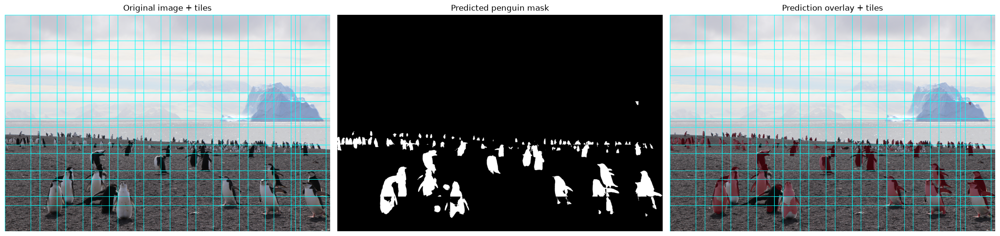

  Finished: penguins_far.jpg

Image 2/2: penguins_near.jpg
  Image size: 5184 × 3456
  Number of tiles: 77
  Processed 25/77 tiles
  Processed 50/77 tiles
  Processed 75/77 tiles


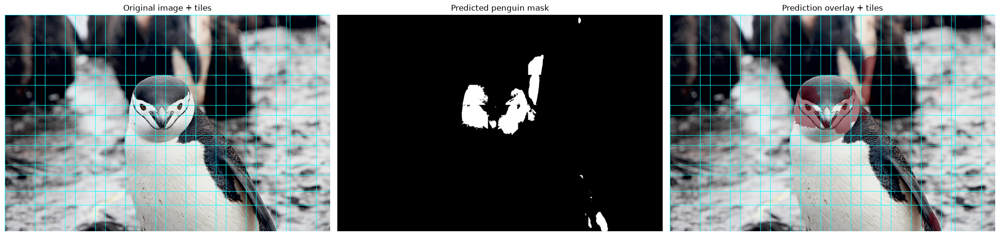

  Finished: penguins_near.jpg


In [4]:
image_paths = sorted(
    path
    for path in TEST_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

if len(image_paths) != num_examples:
    raise ValueError(
        f"Expected 6 test images, found {len(image_paths)} in {TEST_DIR}"
    )

for index, image_path in enumerate(image_paths, start=1):
    print(f"\n{'=' * 60}")
    print(f"Image {index}/{len(image_paths)}: {image_path.name}")
    print(f"{'=' * 60}")

    with Image.open(image_path) as img:
        image = ImageOps.exif_transpose(img).convert("RGB")

    print(f"  Image size: {image.width} × {image.height}")

    prediction, tiles = predict_with_tiles(image)

    show_result(
        image=image,
        prediction=prediction,
        tiles=tiles,
        show_indices=False,
    )

    print(f"  Finished: {image_path.name}")

    # Process one full-resolution image at a time.
    del image, prediction, tiles